[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_figures_MA_A.ipynb)

# Part A: the tables and figures of the report

Reads what the runs of `colab_train_MA_A.ipynb` saved on Drive (`results.json`, `hparams.yaml`, the TensorBoard logs and the analysis files) and draws the tables and figures of the report. Nothing is trained here, so a CPU runtime is enough and it takes about a minute.

1. **Table 1 (A3)**: top-1 / top-5 on the test set, for every encoder.
2. **Figure 1 (A2)**: validation reconstruction error against k-NN accuracy, across all tuning trials.
3. **Figure 2 (A2)**: the same two numbers along the epochs of the final DAE and AE.
4. **Figure 3 (A4)**: accuracy against the label fraction.
5. **Figure 4 (A4 bonus)**: the robustness test.
6. **A5**: where the representation fails, and the saved retrieval grid and t-SNE.

## Setup
Mounts Drive. `FINAL` holds the 47 final runs, `TUNING` the tuning runs, and every figure is saved to `FIGURES`.

In [2]:
import glob
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from google.colab import drive
from IPython.display import Image, display
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע"
FINAL = f"{DRIVE_DIR}/midterm_final"
TUNING = f"{DRIVE_DIR}/midterm_runs"
FIGURES = f"{DRIVE_DIR}/figures"
os.makedirs(FIGURES, exist_ok=True)

plt.style.use("ggplot")
ENCODERS = ["DAE", "AE", "Random", "Supervised"]  # the order of every table and legend
DATASETS = ["TinyImageNet", "CIFAR100"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## The final runs
One row per run: its settings from `hparams.yaml` and its test numbers from `results.json`.

In [3]:
rows = []
for path in sorted(glob.glob(f"{FINAL}/date*/results.json")):
    run = os.path.dirname(path)
    with open(f"{run}/hparams.yaml", encoding="utf-8") as f:
        hp = yaml.safe_load(f)
    with open(path) as f:
        results = json.load(f)
    name = os.path.basename(str(hp["ENCODER_PATH"]))  # the encoder file the run loads or saves
    if name.startswith("supervised"):
        encoder = "Supervised"
    elif name.startswith("dae"):
        encoder = "AE" if hp["NOISE_LEVEL"] == 0 else "DAE"
    else:
        encoder = "Random"
    rows.append({"run": run, "mode": hp["MODE"], "encoder": encoder, "dataset": hp["DATASET"],
                 "labels": hp["LABEL_FRACTION"], **results})
runs = pd.DataFrame(rows)

# k-NN runs report test_knn_top1, the classifiers test_accuracy
runs["top1"] = runs["test_accuracy"].fillna(runs["test_knn_top1"])
runs["top5"] = runs["test_top5_accuracy"].fillna(runs["test_knn_top5"])
runs["score"] = runs["top1"].map("{:.3f}".format) + " / " + runs["top5"].map("{:.3f}".format)
print(len(runs), "runs")
print(runs.groupby(["mode", "encoder"]).size().unstack(fill_value=0))

47 runs
encoder                     AE  DAE  Random  Supervised
mode                                                   
analysis                     2    2       2           2
finetune                     6    6       6           0
knn                          2    2       2           2
linear_probe                 2    2       2           2
pretrain                     1    1       0           0
pretrain_supervise_encoder   0    0       0           3


## Table 1 (A3): the baselines
Top-1 / top-5 on the test set. The first table is the frozen encoder (k-NN and linear probe), the second is training with 1%, 10% and 100% of the labels: fine-tuning for the DAE, the AE and the random encoder, training from scratch for the supervised one.

In [4]:
frozen = runs[runs["mode"].isin(["knn", "linear_probe"])]
table_frozen = frozen.pivot(index="encoder", columns=["dataset", "mode"], values="score").reindex(ENCODERS)
display(table_frozen)

labeled = runs[runs["mode"].isin(["finetune", "pretrain_supervise_encoder"])]
table_labels = labeled.pivot(index="encoder", columns=["dataset", "labels"], values="score").reindex(ENCODERS).fillna("")
display(table_labels)

table_frozen.to_csv(f"{FIGURES}/table1_frozen.csv")
table_labels.to_csv(f"{FIGURES}/table1_labels.csv")

dataset      TinyImageNet                      CIFAR100               
mode                  knn   linear_probe            knn   linear_probe
encoder                                                               
DAE         0.102 / 0.237  0.093 / 0.248  0.233 / 0.483  0.222 / 0.470
AE          0.081 / 0.199  0.090 / 0.235  0.227 / 0.465  0.206 / 0.450
Random      0.049 / 0.137  0.074 / 0.210  0.185 / 0.401  0.193 / 0.431
Supervised  0.275 / 0.506  0.299 / 0.541  0.332 / 0.596  0.364 / 0.661

dataset      TinyImageNet                                     CIFAR100  \
labels               0.01           0.10           1.00           0.01   
encoder                                                                  
DAE         0.043 / 0.133  0.160 / 0.361  0.294 / 0.550  0.088 / 0.256   
AE          0.044 / 0.129  0.169 / 0.372  0.303 / 0.565  0.096 / 0.261   
Random      0.040 / 0.124  0.145 / 0.326  0.314 / 0.565  0.086 / 0.253   
Supervised  0.039 / 0.122  0.142 / 0.326  0.296 / 0.547                  

dataset                                   
labels               0.10           1.00  
encoder                                   
DAE         0.213 / 0.462  0.427 / 0.718  
AE          0.247 / 0.512  0.424 / 0.724  
Random      0.226 / 0.483  0.392 / 0.686  
Supervised

## Figure 1 (A2): reconstruction error against k-NN, across all trials
(a) the proxy search (10% of the images), one point per trial, without the trials that diverged. (b) the trials on all the images. ρ is the Spearman correlation.

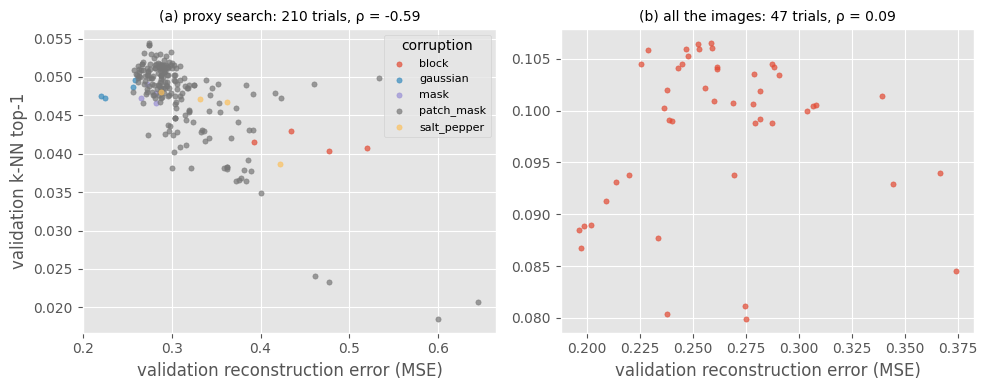

In [5]:
proxy = pd.read_csv(f"{TUNING}/dae_grid_results_all.csv").rename(columns={"val_knn": "val_knn_top1"})
proxy = proxy[proxy["val_loss"] < 0.9]  # a diverged trial has a loss of about 1
full = []
for path in glob.glob(f"{TUNING}/date*_CNN3_tune_pretrain_*/results.json"):
    with open(path) as f:
        full.append(json.load(f))
full = pd.DataFrame(full)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for noise, group in proxy.groupby("noise_type"):
    axes[0].scatter(group["val_loss"], group["val_knn_top1"], s=14, alpha=0.7, label=noise)
axes[0].legend(title="corruption", fontsize=8)
axes[1].scatter(full["val_loss"], full["val_knn_top1"], s=14, alpha=0.7)
for ax, trials, title in zip(axes, [proxy, full], ["(a) proxy search", "(b) all the images"]):
    rho = trials["val_loss"].corr(trials["val_knn_top1"], method="spearman")
    ax.set_title(f"{title}: {len(trials)} trials, ρ = {rho:.2f}", fontsize=10)
    ax.set_xlabel("validation reconstruction error (MSE)")
axes[0].set_ylabel("validation k-NN top-1")
fig.tight_layout()
fig.savefig(f"{FIGURES}/fig1_reconstruction_vs_knn.png", dpi=200)
plt.show()

## Figure 2 (A2): along the epochs of the final DAE and AE
The same two numbers per epoch, from the TensorBoard logs. ★ is the epoch that was kept (the best val k-NN).

DAE: best val k-NN 0.1056 at epoch 10, 0.0926 at epoch 20; val loss 0.2572 then, lowest 0.2430 at epoch 17
AE: best val k-NN 0.0865 at epoch 5, 0.0798 at epoch 20; val loss 0.2187 then, lowest 0.2105 at epoch 13


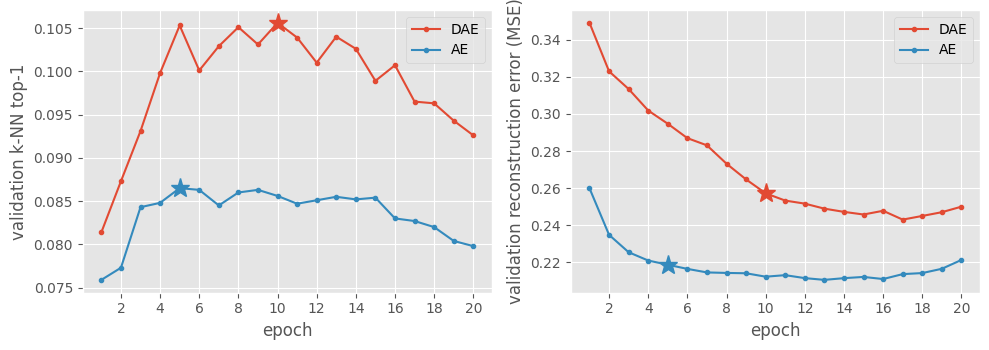

In [6]:
def epoch_curve(run, tag):
    """One scalar of a run per epoch, from its TensorBoard log."""
    for path in glob.glob(f"{run}/events*"):
        log = EventAccumulator(path)
        log.Reload()
        if tag in log.Tags()["scalars"]:
            return pd.Series([event.value for event in log.Scalars(tag)], index=range(1, len(log.Scalars(tag)) + 1))


pretrain = runs[runs["mode"] == "pretrain"].set_index("encoder")["run"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for encoder in ["DAE", "AE"]:
    knn = epoch_curve(pretrain[encoder], "epoch/val_knn_top1")
    loss = epoch_curve(pretrain[encoder], "epoch/val_loss")
    line, = axes[0].plot(knn.index, knn, marker="o", ms=3, label=encoder)
    axes[0].plot(knn.idxmax(), knn.max(), marker="*", ms=14, color=line.get_color())
    axes[1].plot(loss.index, loss, marker="o", ms=3, label=encoder)
    axes[1].plot(knn.idxmax(), loss[knn.idxmax()], marker="*", ms=14, color=line.get_color())
    print(f"{encoder}: best val k-NN {knn.max():.4f} at epoch {knn.idxmax()}, {knn.iloc[-1]:.4f} at epoch {len(knn)}; "
          f"val loss {loss[knn.idxmax()]:.4f} then, lowest {loss.min():.4f} at epoch {loss.idxmin()}")
axes[0].set_ylabel("validation k-NN top-1")
axes[1].set_ylabel("validation reconstruction error (MSE)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_xticks(range(2, len(knn) + 1, 2))
    ax.legend()
fig.tight_layout()
fig.savefig(f"{FIGURES}/fig2_epochs.png", dpi=200)
plt.show()

## Figure 3 (A4): label efficiency
Test top-1 against the share of the labels. DAE, AE and Random are fine-tuned with all weights; Supervised is trained from scratch on Tiny-ImageNet with the same recipe (Random differs from it only in the 3 times larger learning rate of the head).

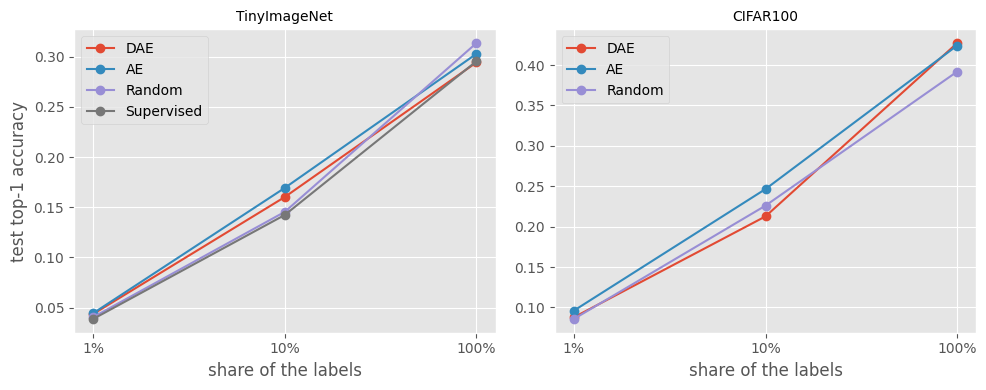

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, dataset in zip(axes, DATASETS):
    for encoder in ENCODERS:
        line = labeled[(labeled["dataset"] == dataset) & (labeled["encoder"] == encoder)].sort_values("labels")
        if len(line):
            ax.plot(line["labels"] * 100, line["top1"], marker="o", label=encoder)
    ax.set_xscale("log")
    ax.set_xticks([1, 10, 100], ["1%", "10%", "100%"])
    ax.minorticks_off()
    ax.set_title(dataset, fontsize=10)
    ax.set_xlabel("share of the labels")
    ax.legend()
axes[0].set_ylabel("test top-1 accuracy")
fig.tight_layout()
fig.savefig(f"{FIGURES}/fig3_label_efficiency.png", dpi=200)
plt.show()

## Figure 4 (A4 bonus): robustness
k-NN top-1 on corrupted test images against a clean bank, from `robustness.csv` of the analysis runs. The table is the share of the clean accuracy that is kept.

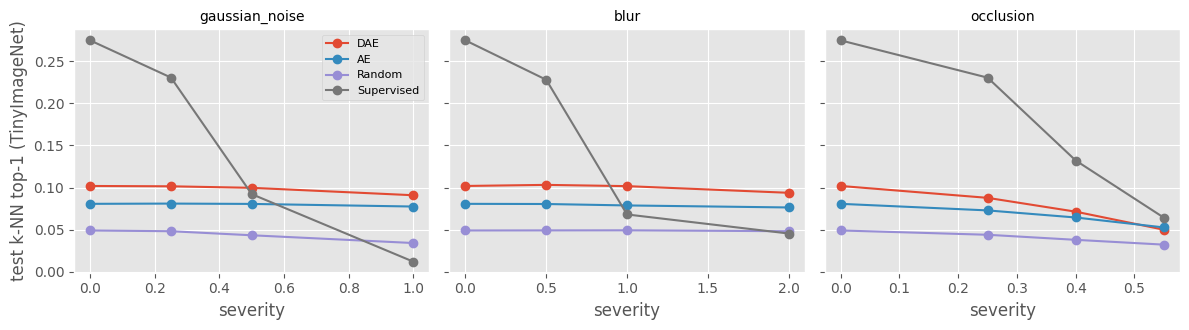

,gaussian_noise_0.25,gaussian_noise_0.5,gaussian_noise_1.0,blur_0.5,blur_1.0,blur_2.0,occlusion_0.25,occlusion_0.4,occlusion_0.55
encoder,,,,,,,,,
DAE,1.00,0.98,0.89,1.01,1.00,0.92,0.86,0.70,0.49
AE,1.00,1.00,0.96,1.00,0.98,0.95,0.90,0.80,0.65
Random,0.98,0.88,0.70,1.00,1.00,0.98,0.90,0.77,0.66
Supervised,0.84,0.34,0.04,0.83,0.25,0.17,0.84,0.48,0.23


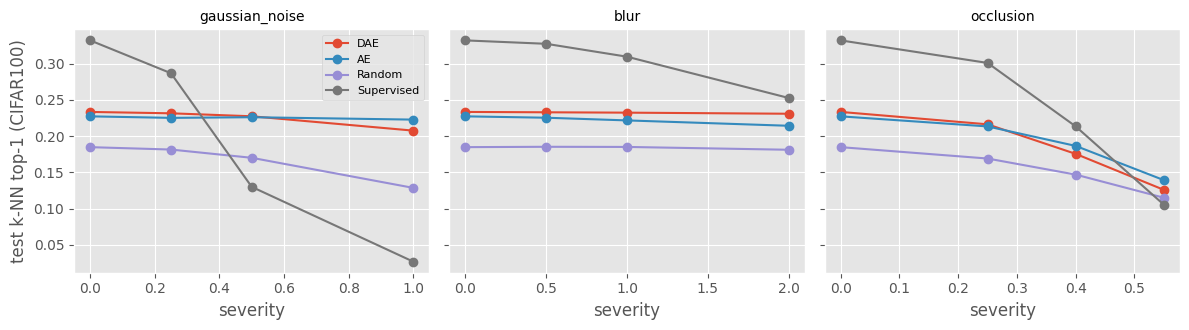

,gaussian_noise_0.25,gaussian_noise_0.5,gaussian_noise_1.0,blur_0.5,blur_1.0,blur_2.0,occlusion_0.25,occlusion_0.4,occlusion_0.55
encoder,,,,,,,,,
DAE,0.99,0.97,0.89,1.00,1.00,0.99,0.93,0.75,0.54
AE,0.99,0.99,0.98,0.99,0.98,0.94,0.94,0.82,0.61
Random,0.98,0.92,0.70,1.00,1.00,0.98,0.91,0.79,0.62
Supervised,0.86,0.39,0.08,0.99,0.93,0.76,0.91,0.64,0.32


In [8]:
analysis = runs[runs["mode"] == "analysis"]
CORRUPTIONS = ["gaussian_noise", "blur", "occlusion"]

for dataset in DATASETS:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
    for encoder in ENCODERS:
        run = analysis[(analysis["dataset"] == dataset) & (analysis["encoder"] == encoder)]["run"].item()
        table = pd.read_csv(f"{run}/robustness.csv")
        for ax, corruption in zip(axes, CORRUPTIONS):
            curve = table[table["corruption"].isin(["none", corruption])]  # severity 0 is the clean test set
            ax.plot(curve["severity"], curve["test_knn_top1"], marker="o", label=encoder)
    for ax, corruption in zip(axes, CORRUPTIONS):
        ax.set_title(corruption, fontsize=10)
        ax.set_xlabel("severity")
    axes[0].set_ylabel(f"test k-NN top-1 ({dataset})")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(f"{FIGURES}/fig4_robustness_{dataset}.png", dpi=200)
    plt.show()

    scores = analysis[analysis["dataset"] == dataset].set_index("encoder").reindex(ENCODERS)
    kept = scores.filter(like="robust_").div(scores["test_knn_top1"], axis=0)
    kept.columns = kept.columns.str.replace("robust_", "")
    display(kept.round(2))
    kept.to_csv(f"{FIGURES}/table_robustness_kept_{dataset}.csv")

## A5: where the representation fails, and extra evidence
The classes the DAE's k-NN gets right least and most often, its most confused pairs, and the saved retrieval grid and t-SNE.

TinyImageNet | lowest: {'n01641577': 0.0, 'n01742172': 0.0, 'n02236044': 0.0, 'n02808440': 0.0, 'n02480495': 0.0} | highest: {'n02423022': 0.38, 'n14991210': 0.44, 'n02074367': 0.5, 'n03393912': 0.5, 'n01910747': 0.54}


,true,predicted,count,share_of_true_class
0,n04251144,n02074367,12,0.24
1,n01770393,n01774384,10,0.20
2,n02129165,n02423022,9,0.18
3,n07753592,n14991210,8,0.16
4,n07875152,n14991210,8,0.16


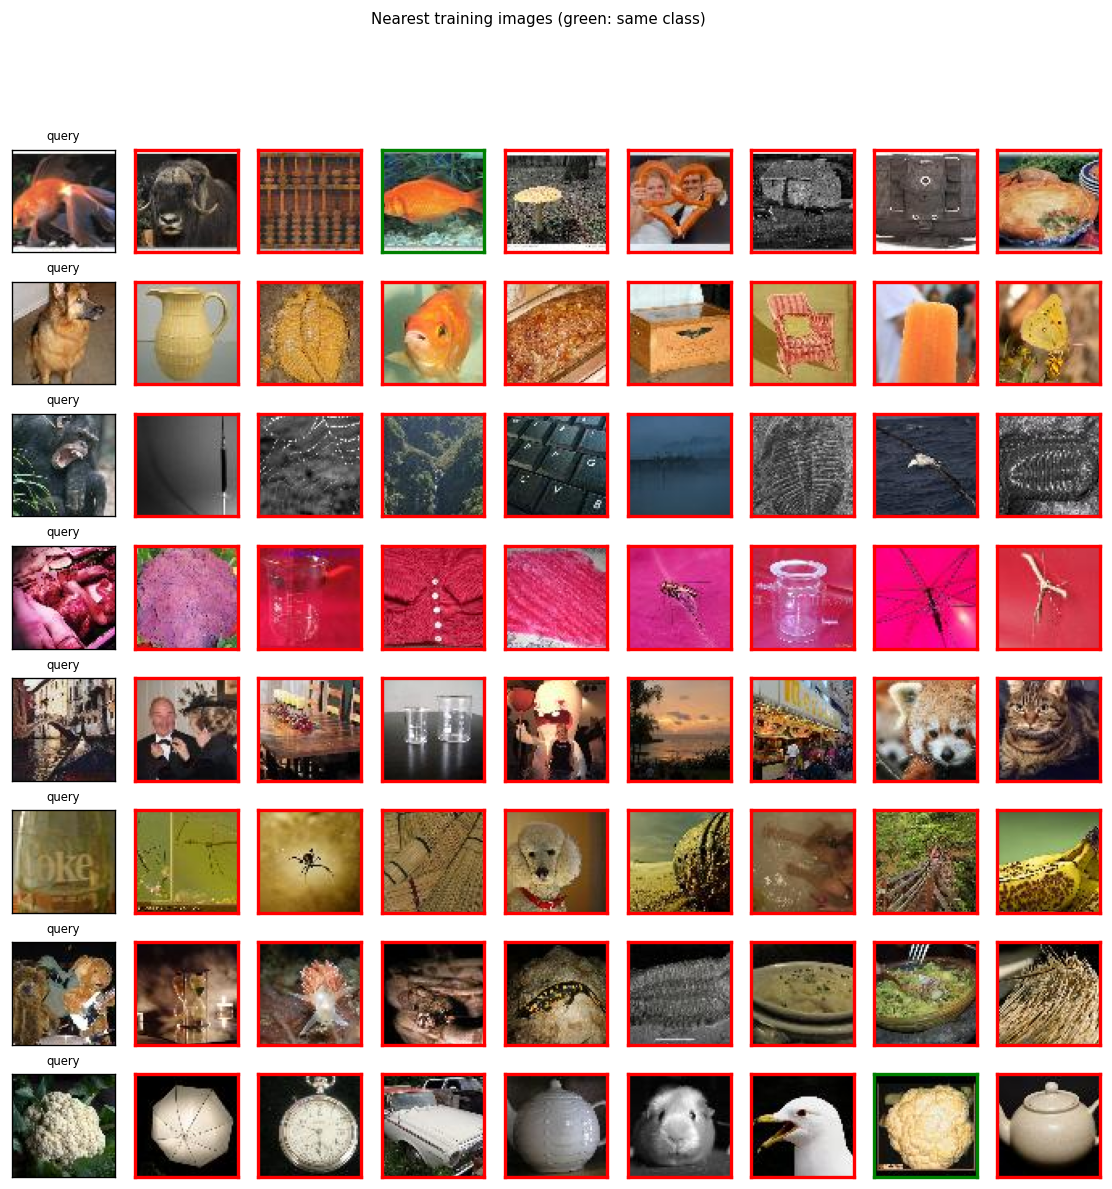

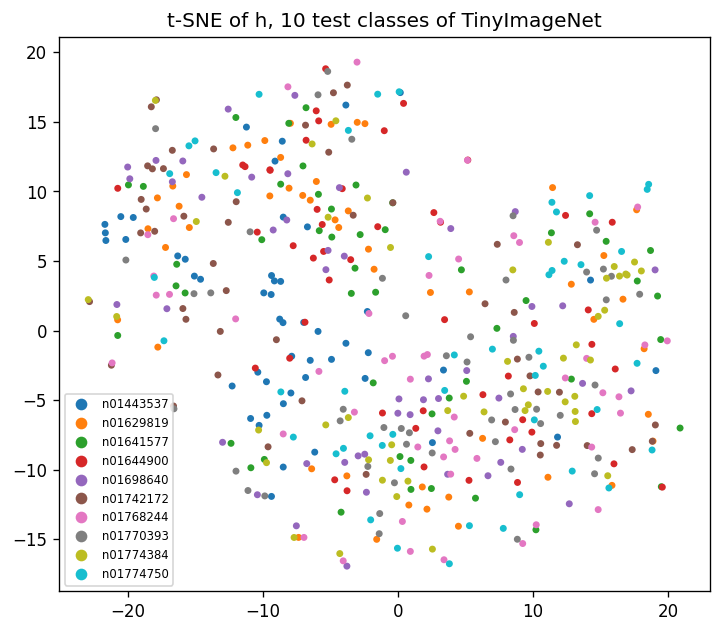

CIFAR100 | lowest: {'house': 0.01, 'bus': 0.04, 'couch': 0.04, 'crocodile': 0.04, 'raccoon': 0.04} | highest: {'sunflower': 0.57, 'orange': 0.6, 'cockroach': 0.64, 'oak_tree': 0.71, 'plain': 0.75}


,true,predicted,count,share_of_true_class
0,pine_tree,oak_tree,28,0.28
1,maple_tree,oak_tree,27,0.27
2,castle,plain,24,0.24
3,sweet_pepper,orange,23,0.23
4,orchid,rose,22,0.22


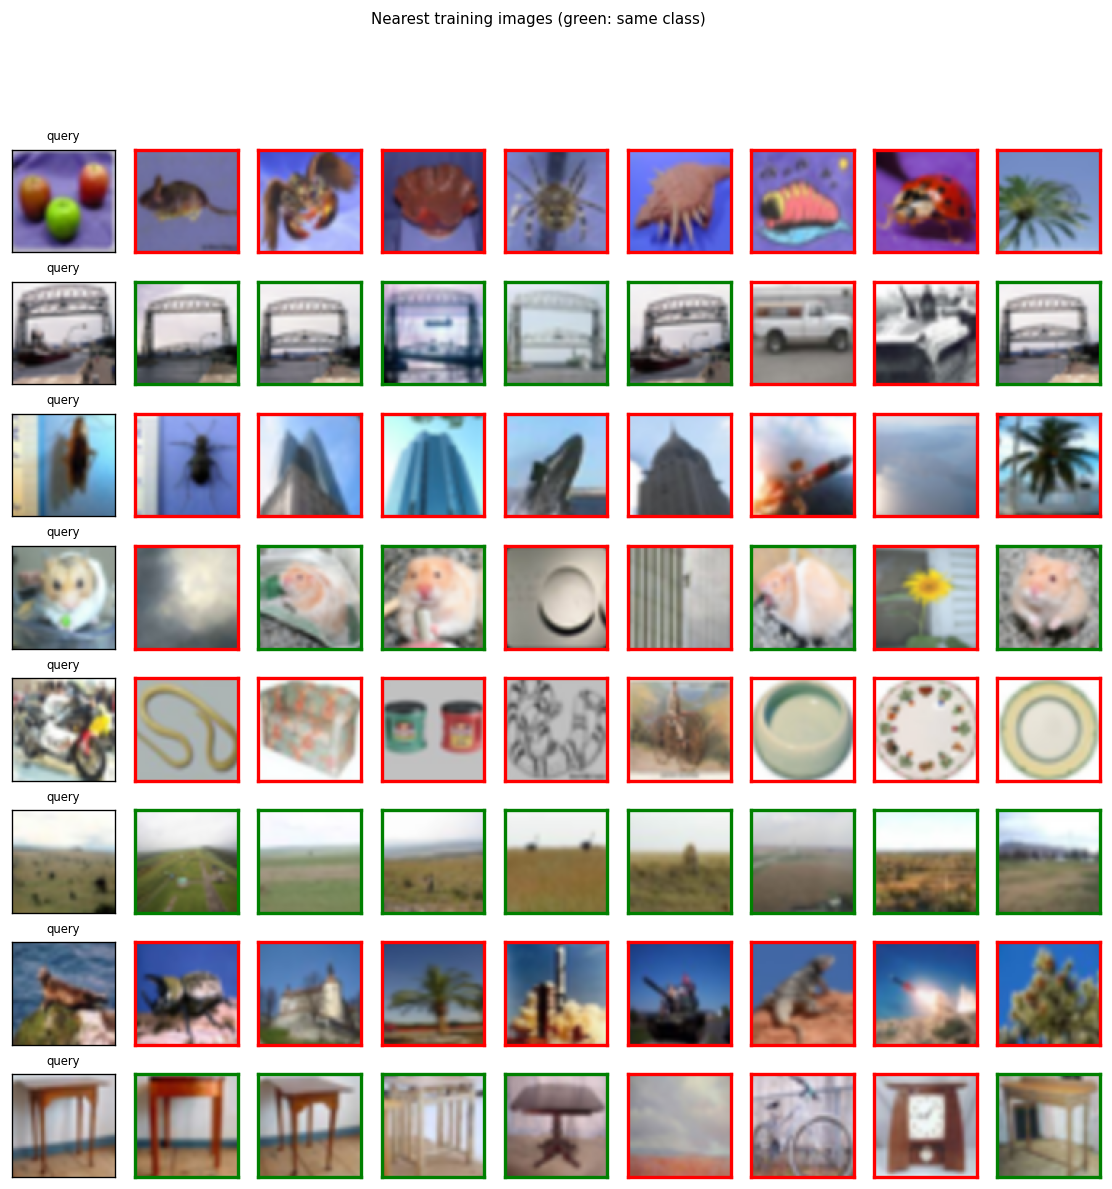

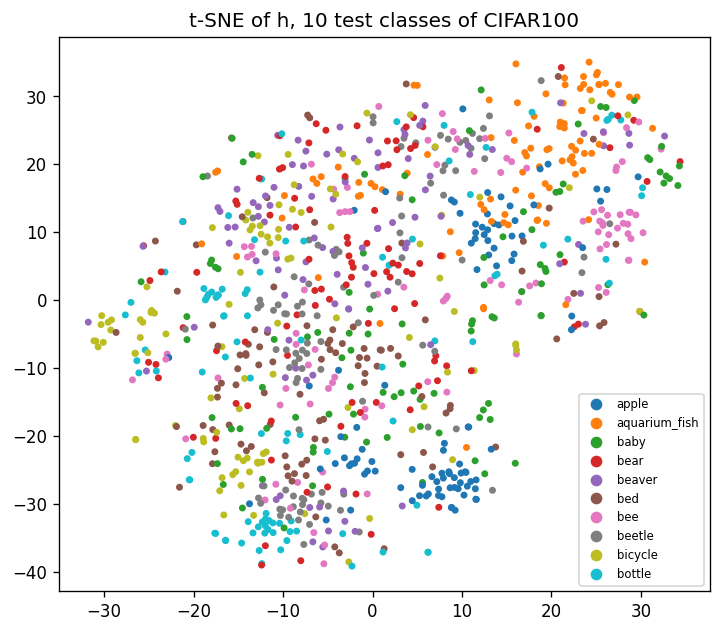

In [9]:
for dataset in DATASETS:
    run = analysis[(analysis["dataset"] == dataset) & (analysis["encoder"] == "DAE")]["run"].item()
    classes = pd.read_csv(f"{run}/per_class_accuracy.csv").sort_values("accuracy")
    print(dataset, "| lowest:", dict(classes.head(5).values), "| highest:", dict(classes.tail(5).values))
    display(pd.read_csv(f"{run}/knn_most_confused.csv").head(5))
    display(Image(f"{run}/retrieval.png", width=700))
    display(Image(f"{run}/tsne.png", width=450))